![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
## Desafio 3
---

## 1. Contexto

Uma loja online do Reino Unido vende presentes e artigos de decoração, principalmente para atacadistas. A equipe de compras precisa prever **a demanda de um produto no dia seguinte**, para separar o estoque do dia. Hoje ela usa uma regra simples: a **média dos últimos quatro mesmos dias da semana** (por exemplo, a previsão de uma segunda-feira é a média das quatro segundas-feiras anteriores).

Você faz parte da equipe de análise de dados e vai **escolher um produto** do catálogo, com base na sua análise do dataset. A diretoria quer saber: **modelos de Machine Learning preveem a demanda desse produto melhor do que um SARIMA e do que a regra atual da equipe?** Para responder, você vai montar os dados, construir os modelos e compará-los com o mesmo critério, em um período de teste que nenhum modelo viu no treino.

Nas Aulas 5 e 6, você viu:

* o **SARIMA**, a sazonalidade (em dados diários, o ciclo é de 7 dias) e a escolha da ordem por **grid search**
* como transformar a série em uma **tabela supervisionada**, com atributos de **lag**, **estatísticas móveis** (só do passado) e **calendário**
* **Regressão Linear**, **KNN**, **Random Forest** e **XGBoost** aplicados a séries temporais
* a **divisão cronológica** em treino e teste, os **baselines** e as **métricas de erro**

## 2. Objetivo

Comparar, para um produto à sua escolha, o **SARIMA** com **modelos de Machine Learning** na previsão da demanda diária, e descobrir o que faz o Machine Learning ganhar ou perder.

Você deverá:

1. Carregar e limpar o dataset, analisá-lo e **escolher um produto**, justificando o critério
2. Montar a demanda diária e o preço relativo do produto escolhido
3. Escolher a métrica de erro e medir o erro dos baselines no período de teste
4. Escolher a ordem do SARIMA por grid search, ajustar o modelo e medir o erro
5. Montar a tabela supervisionada e treinar os quatro modelos de Machine Learning do notebook da Aula 6 (Regressão Linear, KNN, Random Forest e XGBoost)
6. Comparar todos os modelos (Naive, média de 4 semanas, SARIMA e os quatro de Machine Learning)
7. Escrever a conclusão

## 3. Dataset: vendas de uma loja online (Online Retail)

O dataset é o **Online Retail**, do repositório da UCI. Cada linha é um item de uma nota de venda.

Características principais:

* **Período:** de 01/12/2010 a 09/12/2011 (541.909 linhas)
* **Colunas principais:** `InvoiceNo` (nota), `StockCode` (código do produto), `Description` (descrição), `Quantity` (quantidade vendida), `InvoiceDate` (data e hora) e `UnitPrice` (preço)
* **Demanda:** nesta atividade, é a soma de `Quantity` por dia, do produto escolhido

O arquivo está no repositório da disciplina, em formato `.csv`:

```
https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/datasets/online_retail.csv
```

## 4. Escopo e limitações

Para manter o desafio focado no que vimos até aqui, valem estas regras. Elas também são **assunto da sua conclusão**.

1. A demanda é a **quantidade vendida por dia** (dias corridos) de **um único produto**, de **06/12/2010 a 04/12/2011** (364 dias, ou 52 semanas completas)
2. **A escolha do produto é sua**, a partir da análise do dataset. Defina um critério e justifique-o (por exemplo, a regularidade das vendas ao longo do ano e o volume vendido). Um produto que vende em poucos dias tem a série quase toda zerada, e nenhum modelo tem o que aprender
3. A loja não vende aos sábados e fecha em feriados. Esses dias entram na tabela com demanda zero, mas ficam **fora da avaliação**: só contam os dias em que a loja vendeu algum produto (a loja inteira, e não só o seu produto)
4. O **treino** vai de 06/12/2010 a 09/10/2011 (308 dias) e o **teste** de 10/10/2011 a 04/12/2011 (56 dias). O horizonte é de **1 dia à frente**: cada previsão usa o histórico até o dia anterior
5. Todos os modelos usam só o histórico do produto escolhido. A ordem do SARIMA vem de um grid search feito **só com o treino**, e o teste só serve para medir o erro final
6. A variável externa é o **preço relativo** do produto no dia (o preço do dia dividido pelo preço médio do produto). Considere que o preço do dia é conhecido na hora da previsão, como um preço planejado pela loja
7. A **métrica de erro é escolha sua**, entre as que vimos nas aulas. Justifique a escolha, medindo o erro só nos dias com a loja aberta
8. Os atributos usam **só o passado**: nenhuma informação do dia previsto, exceto o calendário e o preço planejado
9. O teste cai em outubro e novembro, época de alta de vendas do fim de ano, o histórico tem só um ano e o resultado vale para o produto que você escolheu. Isso limita as conclusões

## 5. Tarefas

Você deverá realizar as seguintes tarefas, na ordem. Tudo o que você precisa para resolvê-las está neste enunciado. Escreva a sua solução nas células abaixo do header **Sua parte**, no fim do notebook.

### 1. Carregar, limpar, analisar e escolher o produto

1. O dataset já foi carregado no exemplo (`df`). Remova os cancelamentos, as linhas com quantidade ou preço inválidos e os códigos que não são produtos
2. Fique só com as vendas de 06/12/2010 a 04/12/2011 (semanas completas)
3. Monte a tabela `vendas`: um dia por linha, **todos os dias do período** (os dias sem venda valem zero) e uma coluna por produto. Crie a série booleana `aberta`, com um valor por dia: verdadeiro se a loja vendeu algum produto naquele dia
4. Analise os produtos (por exemplo, em quantos dias cada um vendeu e quantas unidades vendeu), **escolha um produto** e escreva em uma célula de texto o critério da escolha
5. Crie a série `demanda`, com a venda diária do produto escolhido, e a série `preco`, com o **preço relativo**: use o preço médio do dia, preencha os dias sem venda com o último preço conhecido (e os primeiros dias com o primeiro preço conhecido) e divida pela média do produto
6. Plote a demanda diária do produto e descreva o padrão da semana

### 2. Baselines

1. Calcule, para cada dia do teste, a previsão do **Naive** (a demanda de ontem) e a da **média de 4 semanas** (a média da demanda dos mesmos dias da semana nas 4 semanas anteriores: 7, 14, 21 e 28 dias antes). Cada previsão é uma série com os dias do teste
2. Escolha a **métrica de erro** (veja o Escopo) e escreva em uma célula de texto por que ela é adequada a este problema
3. Meça o erro de cada baseline com a métrica escolhida, só nos dias com a loja aberta

### 3. SARIMA com grid search

1. Faça um **grid search** da ordem do SARIMA com a diferenciação fixa (d = 0 e D = 1) e o ciclo de 7 dias. Teste `p` e `q` de 0 a 2, e `P` e `Q` de 0 a 1, ajustando cada combinação **só com o treino**
2. Escolha a combinação de menor **AIC** (critério do treino, que não usa o teste)
3. Ajuste o SARIMA com a ordem escolhida **só com o treino** e obtenha a previsão de **1 dia à frente** para cada dia do teste: os parâmetros ficam fixos, e o modelo só incorpora a demanda que vai sendo observada (como no tópico 6.1 do notebook da Aula 6). Não deixe a previsão ficar negativa
4. Avalie com a métrica escolhida

### 4. Tabela supervisionada

1. Monte uma tabela com a demanda do dia (`y`) e os **atributos que você escolher**. A escolha é sua: defina quais atributos fazem sentido para este produto e escreva em uma célula de texto o que usou e por quê. Todos devem usar só o passado (veja o Escopo), e o preço relativo do dia pode entrar
2. Descarte as linhas com atributos vazios (os primeiros dias)
3. Separe as linhas de treino e de teste pelas datas do Escopo (item 4)

### 5. Modelos de Machine Learning

Os quatro modelos do notebook da Aula 6 treinam na mesma tabela de treino, e cada um recebe os atributos que fazem sentido para ele.

1. Treine uma **Regressão Linear**. Ela não entende um atributo de calendário (como o dia da semana) como número: troque os atributos de calendário que você usou por colunas 0/1
2. Separe uma **validação dentro do treino** (os últimos dias do treino) e use-a para **escolher os hiperparâmetros** do KNN, do Random Forest e do XGBoost, como no exercício 2 do notebook da Aula 6. O teste não entra na escolha. Escreva em uma célula de texto os valores escolhidos
3. Treine o **KNN** (com os atributos da Regressão Linear, padronizados com a escala do treino), o **Random Forest** e o **XGBoost** (os dois com os atributos originais, sem escala) no treino completo, com os hiperparâmetros escolhidos. Fixe a semente (`random_state`) e use todos os núcleos do processador nos modelos de árvores
4. Preveja o teste com cada modelo (sem valores negativos), transforme as previsões em séries com os dias do teste e avalie com a métrica escolhida

### 6. Comparar e investigar

1. Monte uma tabela com o erro de cada modelo (os baselines, o SARIMA e os quatro de Machine Learning) na métrica escolhida. Plote o erro em um gráfico de barras

### 7. Conclusão

Em uma célula de texto, escreva uma conclusão curta, com:

1. Qual foi o melhor modelo, e se ele melhora o erro em relação à regra atual da equipe (a média de 4 semanas) e quanto
2. Como ficaram o SARIMA e cada modelo de Machine Learning (Regressão Linear, KNN, Random Forest e XGBoost) e, se você investigou, como a função de perda afetou o resultado do XGBoost
3. Se você investigou o preço, se ele ajuda neste produto e quanto, e o que isso mostra sobre a vantagem do Machine Learning (aceitar variáveis externas)
4. As limitações: um único produto e um único ano de histórico, o teste na alta de fim de ano, a grade pequena do SARIMA e o ajuste dos hiperparâmetros feito em uma única validação e em grades pequenas

> **Dicas:**
>
> * O dataset tem códigos de produto que são números e outros que terminam em letra (por exemplo, `85123A`): trate o código como texto
> * Cancelamentos têm `InvoiceNo` começando com a letra `C`. Códigos que não são produtos (`POST`, `DOT`, `M`) não começam com 5 dígitos
> * Para somar por dia e por produto, agrupe pela data (sem a hora) e pelo código e depois coloque os produtos nas colunas. Para incluir os dias sem nenhuma venda, reindexe pelo calendário completo
> * Para a previsão de 1 dia à frente com os parâmetros fixos, ajuste o modelo só com o treino e use o método `apply` do modelo ajustado na série completa, seguido de `get_prediction`, como no notebook da Aula 6
> * No grid search, ajuste um `SARIMAX` para cada combinação de ordens (as combinações saem do `itertools.product`), guarde o `aic` do modelo ajustado e escolha o menor. São 36 combinações
> * Para escolher o produto, conte em quantos dias cada um vendeu, veja o total de unidades e plote as candidatas. Prefira um produto que venda na maior parte das semanas do ano
> * Os atributos de passado saem do deslocamento da própria série, como no notebook da Aula 6. Se usar uma média móvel, calcule-a sobre a série já deslocada em 1 dia, para não usar o dia previsto
> * Faixas para começar o ajuste dos hiperparâmetros: no KNN, o número de vizinhos entre 3 e 50. No Random Forest, o número de árvores entre 100 e 300, a profundidade máxima entre 3 e 10 (ou sem limite) e o mínimo de linhas por folha entre 1 e 10. No XGBoost, o número de árvores entre 100 e 500, a taxa de aprendizado entre 0,01 e 0,3 e a profundidade entre 2 e 6
> * Para a Regressão Linear e o KNN, use a mesma técnica do notebook da Aula 6: `get_dummies` para os atributos de calendário e `StandardScaler` ajustado só com o treino (e aplicado ao teste). As colunas do teste precisam ficar na mesma ordem das do treino
> * **Para investigar, se o Machine Learning não superar o SARIMA: a função de perda.** A perda que o modelo minimiza no treino deve combinar com a métrica da avaliação. O XGBoost permite trocá-la (argumento `objective`)
> * **Para investigar: a variável de preço.** Para saber o quanto a variável externa ajuda, treine de novo o melhor modelo de Machine Learning sem a coluna de preço e compare

## Setup

* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos
* `statsmodels`: o modelo `SARIMAX`, usado para o SARIMA
* `sklearn`: `LinearRegression`, `KNeighborsRegressor`, `RandomForestRegressor` e o `StandardScaler`
* `xgboost`: o `XGBRegressor`
* `itertools`: as combinações de ordens do grid search

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX

As constantes do desafio: o endereço do dataset e o primeiro dia do teste.

In [2]:
URL = 'https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/datasets/online_retail.csv'
DIA_TESTE = pd.Timestamp('2011-10-10')

## Exemplo: baixar o dataset e plotar um produto

O código abaixo baixa o dataset (o `.csv` do repositório da disciplina) e plota as vendas diárias de um produto de exemplo, **sem nenhuma limpeza**. O `DataFrame` `df` fica pronto para você usar na tarefa 1. Repare que o código do produto é lido como texto e a data como data.

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536370,10002,INFLATABLE POLITICAL GLOBE,48,2010-12-01 08:45:00,0.85,12583.0,France
1,536382,10002,INFLATABLE POLITICAL GLOBE,12,2010-12-01 09:45:00,0.85,16098.0,United Kingdom
2,536756,10002,INFLATABLE POLITICAL GLOBE,1,2010-12-02 14:23:00,0.85,NaN,United Kingdom
3,536863,10002,INFLATABLE POLITICAL GLOBE,1,2010-12-03 11:19:00,0.85,17967.0,United Kingdom
4,536865,10002,INFLATABLE POLITICAL GLOBE,5,2010-12-03 11:28:00,1.66,NaN,United Kingdom


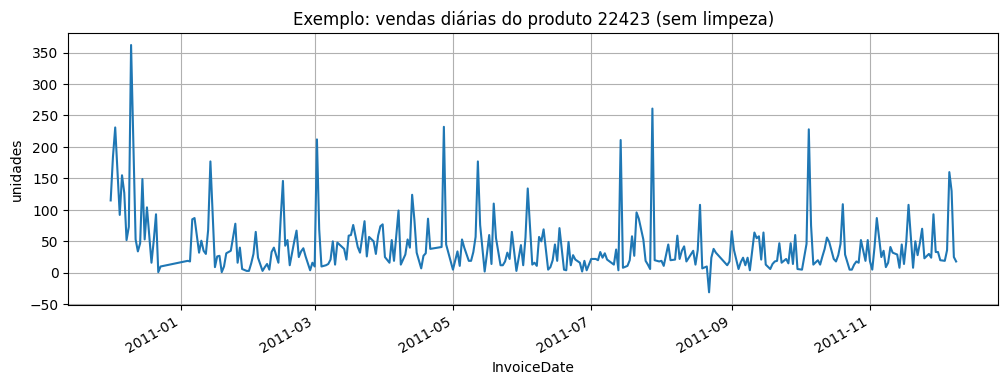

In [3]:
df = pd.read_csv(URL, dtype={'StockCode': str}, parse_dates=['InvoiceDate'])

exemplo = df[df['StockCode'] == '22423']
vendas_exemplo = exemplo.groupby(exemplo['InvoiceDate'].dt.normalize())['Quantity'].sum()
vendas_exemplo.plot(figsize=(12, 4), grid=True, title='Exemplo: vendas diárias do produto 22423 (sem limpeza)', ylabel='unidades')
plt.show()

---
# Sua parte